In [1]:
# Setup: run this cell first (needed on Google Colab; harmless elsewhere).
# Versions are pinned to the ones this workbook was tested with.
%pip install -q "qiskit==2.6.2" "qiskit-aer==0.18.4" "pylatexenc==2.11"

Note: you may need to restart the kernel to use updated packages.


# Workbook 2: The Qubit

**Quantum Computing Course, Workbook 2 of 14.** Prepared by Aditya Sharma.

This workbook is about one qubit: how we describe its state, what a measurement does, and how to estimate probabilities from repeated runs on a simulator. Gates get their own workbook (Workbook 3). Run the setup cell above first.

# How to use this workbook

Part A has the theory notes, Part B the exercises (easy, medium, hard, then Qiskit tasks) and Part C the answer key (instructor edition only). You need Workbook 1: complex numbers, kets and bras, inner products, and shot statistics.

> **Note.** Boxes marked **Note** give tips and context. Boxes marked **Common mistake** flag errors that students make often.

## Learning outcomes

By the end of this workbook you should be able to:

1. Write a general qubit state, check that it is normalised, and normalise it if not.
2. Use the Born rule to compute outcome probabilities in the Z basis and in any other orthonormal basis.
3. Explain the difference between global phase and relative phase, and say which one can be detected.
4. Find the Bloch angles and Bloch vector of a state, and place the six standard states on the Bloch sphere.
5. Compute probabilities for a measurement in the X basis, and explain how a circuit measures in the X basis using only Z-basis readout.
6. Run a circuit for many shots on a simulator, read the histogram, and judge whether a difference from the predicted probability is just statistical noise.

# Part A: Theory notes

## 2.1 The state of a qubit

A **qubit** is a quantum system with two perfectly distinguishable states, which we label $|0\rangle$ and $|1\rangle$. Its state is a normalised ket in $\mathbb{C}^2$:

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad \alpha,\beta \in \mathbb{C}, \qquad \lvert\alpha\rvert^2 + \lvert\beta\rvert^2 = 1 .
$$

The complex numbers $\alpha$ and $\beta$ are called **amplitudes**. The condition $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2 = 1$ is the **normalisation** condition. It says $\langle\psi|\psi\rangle = 1$.

When both amplitudes are nonzero, we say the qubit is in a **superposition** of $|0\rangle$ and $|1\rangle$. A superposition is one definite state. For example $|+\rangle = \frac{1}{\sqrt2}(|0\rangle + |1\rangle)$ is just as definite as $|0\rangle$: it is the state that always gives "+" when measured in the X basis (Section 2.5).

**Normalising a vector.** If a vector $|v\rangle$ is not normalised, divide by its norm: $|\psi\rangle = |v\rangle / \sqrt{\langle v|v\rangle}$.

### Worked example 2.1

Normalise $|v\rangle = |0\rangle + 2i|1\rangle$. We have $\langle v|v\rangle = \lvert 1\rvert^2 + \lvert 2i\rvert^2 = 1 + 4 = 5$, so

$$
|\psi\rangle = \frac{1}{\sqrt5}\left(|0\rangle + 2i|1\rangle\right).
$$

> **Common mistake.** Checking normalisation with $\alpha^2 + \beta^2$ instead of $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2$. For $\frac{1}{\sqrt5}(1, 2i)$ the wrong version gives $\frac{1 - 4}{5} = -\frac35$. The right version gives $\frac{1 + 4}{5} = 1$.

In Qiskit, the `Statevector` class stores amplitudes exactly. It is a calculation on your computer, not a measurement of anything.

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

psi = Statevector(np.array([1, 2j]) / np.sqrt(5))
print("amplitudes  :", np.round(psi.data, 4))
print("is valid    :", psi.is_valid())          # checks normalisation
print("probabilities:", np.round(psi.probabilities(), 4))

amplitudes  : [0.4472+0.j     0.    +0.8944j]
is valid    : True
probabilities: [0.2 0.8]


## 2.2 The Born rule

You cannot read the amplitudes of a qubit directly. What you can do is **measure** it. A measurement in the **computational basis** (also called the **Z basis**) gives outcome 0 or 1. The **Born rule** gives the probabilities:

$$
P(0) = \lvert\langle 0|\psi\rangle\rvert^2 = \lvert\alpha\rvert^2, \qquad P(1) = \lvert\langle 1|\psi\rangle\rvert^2 = \lvert\beta\rvert^2 .
$$

Normalisation is exactly the statement that these probabilities add up to 1.

**After the measurement** the qubit is left in the basis state that matches the outcome: $|0\rangle$ if you saw 0, $|1\rangle$ if you saw 1. Measure again straight away and you get the same answer with certainty. The original amplitudes are gone. One measurement gives you **one bit** of information, however complicated $\alpha$ and $\beta$ were.

**Any orthonormal basis.** The same rule works for any orthonormal basis $\{|b_0\rangle, |b_1\rangle\}$:

$$
P(b_k) = \lvert\langle b_k|\psi\rangle\rvert^2 , \qquad k = 0, 1 .
$$

After the measurement the state is $|b_k\rangle$.

### Worked example 2.2

Take $|\psi\rangle = \frac{1}{2}|0\rangle - \frac{\sqrt3}{2}i\,|1\rangle$. Then $P(0) = \frac14$ and $P(1) = \lvert -\frac{\sqrt3}{2}i\rvert^2 = \frac34$. If the outcome is 1, the qubit is now $|1\rangle$, and a second Z measurement gives 1 again.

> **Common mistake.** Thinking that a measurement reveals values that were "already there" for $\alpha$ and $\beta$. A single shot gives 0 or 1, nothing more. To learn about the amplitudes you need many identically prepared qubits, and even then, Z-basis shots alone only tell you $\lvert\alpha\rvert^2$ and $\lvert\beta\rvert^2$.

## 2.3 Global phase and relative phase

Multiply a state by a phase $e^{i\gamma}$:

$$
|\psi'\rangle = e^{i\gamma}|\psi\rangle .
$$

For any basis state $|b\rangle$, $\lvert\langle b|\psi'\rangle\rvert^2 = \lvert e^{i\gamma}\rvert^2\,\lvert\langle b|\psi\rangle\rvert^2 = \lvert\langle b|\psi\rangle\rvert^2$. So **every** measurement, in **every** basis, gives the same probabilities. A factor in front of the whole state is called a **global phase**, and it has no physical effect. We treat $|\psi\rangle$ and $e^{i\gamma}|\psi\rangle$ as the same physical state. For example, $|1\rangle$, $-|1\rangle$ and $i|1\rangle$ are the same state.

A phase *between* the two amplitudes is different. Compare

$$
|+\rangle = \tfrac{1}{\sqrt2}\left(|0\rangle + |1\rangle\right) \qquad\text{and}\qquad |-\rangle = \tfrac{1}{\sqrt2}\left(|0\rangle - |1\rangle\right).
$$

Here the second amplitude differs by a factor $-1 = e^{i\pi}$, but the first does not. This is a **relative phase**. Both states give $P(0) = P(1) = \frac12$ in the Z basis. But they are orthogonal, $\langle +|-\rangle = 0$, so a measurement in the right basis (the X basis, Section 2.5) tells them apart with certainty.

In general we can always write a state as $\alpha|0\rangle + \beta|1\rangle$ with $\alpha$ real and non-negative, by pulling out a global phase. The relative phase is then the angle of $\beta$.

> **Common mistake.** Concluding that $|+\rangle$ and $|-\rangle$ are "the same" because their Z-basis histograms look the same. Relative phase is invisible in one basis but visible in another.

> **Note.** In Workbook 3 you will meet two phase gates: $P(\lambda) = \mathrm{diag}(1, e^{i\lambda})$ and Qiskit's $R_Z(\lambda) = \mathrm{diag}(e^{-i\lambda/2}, e^{i\lambda/2})$. They differ only by the global phase $e^{-i\lambda/2}$, so they do the same thing to any single-qubit state. The cell below checks this.

In [3]:
from qiskit.quantum_info import Operator
from qiskit.circuit.library import RZGate, PhaseGate

lam = 0.9
RZ = Operator(RZGate(lam)).data
P = Operator(PhaseGate(lam)).data
print("RZ(lam) = e^{-i lam/2} P(lam)?", np.allclose(RZ, np.exp(-1j * lam / 2) * P))

# Global phase: Statevector.equiv ignores it, == does not.
one = Statevector([0, 1])
print("|1> == -|1>      :", one == Statevector([0, -1]))
print("|1> equiv -|1>   :", one.equiv(Statevector([0, -1])))
plus, minus = Statevector([1, 1] / np.sqrt(2)), Statevector([1, -1] / np.sqrt(2))
print("|+> equiv |->    :", plus.equiv(minus))

RZ(lam) = e^{-i lam/2} P(lam)? True
|1> == -|1>      : False
|1> equiv -|1>   : True
|+> equiv |->    : False


## 2.4 The Bloch sphere

Since global phase does not matter, a qubit state has two real degrees of freedom. Pull out the global phase so that $\alpha \geq 0$, and use normalisation. Every single-qubit state can then be written as

$$
|\psi\rangle = \cos\frac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}\,|1\rangle, \qquad 0 \leq \theta \leq \pi, \quad 0 \leq \varphi < 2\pi .
$$

The angles $(\theta, \varphi)$ are the polar and azimuthal angles of a point on a unit sphere, the **Bloch sphere**. The point is the **Bloch vector**

$$
\vec r = \left(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta\right).
$$

- The north pole ($\theta = 0$) is $|0\rangle$ and the south pole ($\theta = \pi$) is $|1\rangle$.
- The height $z = \cos\theta$ fixes the Z-basis probabilities: $P(0) = \cos^2\frac{\theta}{2} = \frac{1+z}{2}$.
- The angle $\varphi$ around the vertical axis is the relative phase.

The six standard states sit where the axes meet the sphere:

| State | Amplitudes | $\theta$ | $\varphi$ | Bloch vector |
|---|---|---|---|---|
| $\lvert 0\rangle$ | $(1, 0)$ | $0$ | any | $(0, 0, 1)$ |
| $\lvert 1\rangle$ | $(0, 1)$ | $\pi$ | any | $(0, 0, -1)$ |
| $\lvert +\rangle$ | $\frac{1}{\sqrt2}(1, 1)$ | $\pi/2$ | $0$ | $(1, 0, 0)$ |
| $\lvert -\rangle$ | $\frac{1}{\sqrt2}(1, -1)$ | $\pi/2$ | $\pi$ | $(-1, 0, 0)$ |
| $\lvert {+i}\rangle$ | $\frac{1}{\sqrt2}(1, i)$ | $\pi/2$ | $\pi/2$ | $(0, 1, 0)$ |
| $\lvert {-i}\rangle$ | $\frac{1}{\sqrt2}(1, -i)$ | $\pi/2$ | $3\pi/2$ | $(0, -1, 0)$ |

**Orthogonal states are opposite points.** $|0\rangle$ and $|1\rangle$ are orthogonal, and they sit at the two poles, $180^\circ$ apart. The same holds for $|+\rangle$ and $|-\rangle$, and for $|{+i}\rangle$ and $|{-i}\rangle$. In general, orthogonal states are antipodal on the Bloch sphere (you prove this in H4).

> **Common mistake.** Drawing $|0\rangle$ and $|1\rangle$ at right angles, as in the $\mathbb{C}^2$ picture. On the Bloch sphere the angle is doubled: $\theta/2$ in the state becomes $\theta$ on the sphere, so orthogonal states end up $180^\circ$ apart.

**Expectation values.** For a Hermitian matrix $A$, the **expectation value** in state $|\psi\rangle$ is $\langle A\rangle = \langle\psi|A|\psi\rangle$. It is the average of the measured eigenvalues over many shots. The three components of the Bloch vector are the expectation values of the Pauli matrices:

$$
x = \langle X\rangle, \qquad y = \langle Y\rangle, \qquad z = \langle Z\rangle .
$$

### Worked example 2.3

Find the Bloch angles of $|\psi\rangle = \frac{1}{2}|0\rangle - \frac{\sqrt3}{2}i\,|1\rangle$ from Worked example 2.2. The first amplitude is already real and positive, so $\cos\frac{\theta}{2} = \frac12$, giving $\theta = \frac{2\pi}{3}$. Then $e^{i\varphi}\sin\frac{\theta}{2} = -\frac{\sqrt3}{2}i$. Since $\sin\frac{\pi}{3} = \frac{\sqrt3}{2}$, we need $e^{i\varphi} = -i$, so $\varphi = \frac{3\pi}{2}$. The Bloch vector is $\left(0, -\frac{\sqrt3}{2}, -\frac12\right)$: below the equator, on the $-y$ side.

Bloch vector: [ 0.    -0.866 -0.5  ]


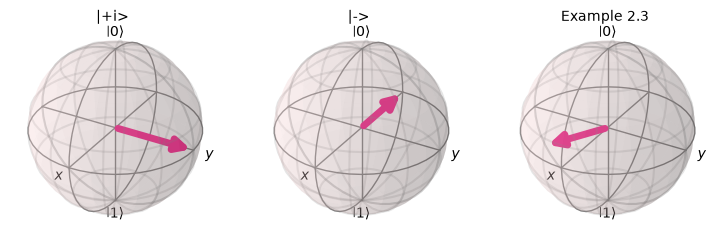

In [4]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_bloch_vector

def bloch_vector(state):
    """Bloch vector (<X>, <Y>, <Z>) of a single-qubit Statevector."""
    from qiskit.quantum_info import Pauli
    return np.array([state.expectation_value(Pauli(p)).real for p in "XYZ"])

psi = Statevector([1 / 2, -np.sqrt(3) / 2 * 1j])
r = bloch_vector(psi)
print("Bloch vector:", np.round(r, 4))

fig = plt.figure(figsize=(9, 3))
for k, (label, vec) in enumerate([("|+i>", [0, 1, 0]), ("|->", [-1, 0, 0]), ("Example 2.3", r)]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    plot_bloch_vector(vec, ax=ax, title=label)
plt.show()

## 2.5 Measurement in the Z and X bases

The **X basis** is $\{|+\rangle, |-\rangle\}$, the eigenvectors of $X$. By the Born rule,

$$
P(+) = \lvert\langle +|\psi\rangle\rvert^2 = \frac{\lvert\alpha + \beta\rvert^2}{2}, \qquad P(-) = \lvert\langle -|\psi\rangle\rvert^2 = \frac{\lvert\alpha - \beta\rvert^2}{2}.
$$

In terms of the Bloch vector, $P(+) = \frac{1 + x}{2}$ and $P(-) = \frac{1 - x}{2}$. So a Z measurement tells you about $z$, and an X measurement tells you about $x$.

### Worked example 2.4

For $|\psi\rangle = \frac{1}{2}|0\rangle - \frac{\sqrt3}{2}i\,|1\rangle$: $\alpha + \beta = \frac12 - \frac{\sqrt3}{2}i$, so $\lvert\alpha+\beta\rvert^2 = \frac14 + \frac34 = 1$ and $P(+) = \frac12$. Likewise $P(-) = \frac12$. This matches $x = 0$ from Worked example 2.3.

For $|+\rangle$: $P(+) = 1$. For $|-\rangle$: $P(+) = 0$. In the Z basis both give 50/50, but in the X basis they are perfectly distinguished.

### How a circuit measures in the X basis

Quantum hardware, and Qiskit's `measure` instruction, read out in the Z basis only. To measure in another basis we first apply a unitary that turns that basis into the Z basis, and then measure in Z. For the X basis that unitary is the Hadamard matrix $H$ from Workbook 1, because

$$
H|+\rangle = |0\rangle, \qquad H|-\rangle = |1\rangle .
$$

So "apply $H$, then measure" gives outcome 0 with probability $P(+)$ and outcome 1 with probability $P(-)$. In this workbook we use $H$ only as this change of basis. Workbook 3 treats it as a gate in its own right.

For the **Y basis** $\{|{+i}\rangle, |{-i}\rangle\}$ the recipe is "apply $S^\dagger$, then $H$, then measure", since $HS^\dagger|{+i}\rangle = |0\rangle$ and $HS^\dagger|{-i}\rangle = |1\rangle$ (check it with the matrices from Workbook 1).

> **Note.** To prepare states in code we use a small helper, `prepare(theta, phi)`. It applies two gates, `ry` and `p`, that rotate $|0\rangle$ to the point $(\theta, \varphi)$ on the Bloch sphere. Treat it as a dial for now. Workbook 3 explains how the gates work.

amplitudes: [ 0.5+0.j    -0. -0.866j]
same state as example 2.3? True


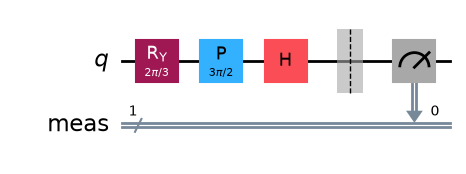

In [5]:
def prepare(theta, phi=0.0):
    """Circuit that prepares cos(theta/2)|0> + e^{i phi} sin(theta/2)|1>."""
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    qc.p(phi, 0)
    return qc

def in_basis(qc, basis):
    """Copy of qc with a change of basis (if needed) and a final measurement."""
    m = qc.copy()
    if basis == "X":
        m.h(0)
    elif basis == "Y":
        m.sdg(0)
        m.h(0)
    m.measure_all()
    return m

# Check the dial against Worked example 2.3: theta = 2 pi/3, phi = 3 pi/2
state = Statevector(prepare(2 * np.pi / 3, 3 * np.pi / 2))
print("amplitudes:", np.round(state.data, 4))
print("same state as example 2.3?", state.equiv(Statevector([1 / 2, -np.sqrt(3) / 2 * 1j])))
in_basis(prepare(2 * np.pi / 3, 3 * np.pi / 2), "X").draw("mpl")

## 2.6 Shots and histograms on a simulator

A quantum program is run many times. Each run is a **shot**, and each shot gives one bit string. The **counts** say how often each string appeared. A **histogram** plots them.

In this course we run circuits on **Qiskit Aer**, a simulator. It runs on the computer in front of you (or on Google's servers, in Colab). It works out the exact probabilities from the state vector and then draws random samples from them. It is *not* quantum hardware, and its default runs have no noise. Running on a real quantum processor comes in Workbook 12.

We use Aer's `SamplerV2`, which has the same interface as the sampler for IBM quantum processors. The helper below runs a circuit and returns its counts.

In [6]:
from qiskit_aer.primitives import SamplerV2 as Sampler
from qiskit.visualization import plot_histogram

seed_source = np.random.default_rng(2027)   # makes this notebook reproducible

def run_counts(qc, shots=1000):
    """Run qc on the Aer simulator (not hardware) and return counts."""
    sampler = Sampler(seed=int(seed_source.integers(1_000_000)))
    result = sampler.run([qc], shots=shots).result()[0]
    return result.data.meas.get_counts()

# Worked example 2.2 state: P(0) = 1/4, P(1) = 3/4
qc = in_basis(prepare(2 * np.pi / 3, 3 * np.pi / 2), "Z")
for shots in [100, 1000, 10000]:
    c = run_counts(qc, shots)
    p1 = c.get("1", 0) / shots
    se = np.sqrt(0.75 * 0.25 / shots)
    print(f"shots={shots:6d}  counts={dict(sorted(c.items()))}  P(1) estimate={p1:.3f}  (exact 0.75, typical error {se:.3f})")

shots=   100  counts={'0': 27, '1': 73}  P(1) estimate=0.730  (exact 0.75, typical error 0.043)
shots=  1000  counts={'0': 242, '1': 758}  P(1) estimate=0.758  (exact 0.75, typical error 0.014)
shots= 10000  counts={'0': 2539, '1': 7461}  P(1) estimate=0.746  (exact 0.75, typical error 0.004)


The estimates scatter around $0.75$, and the scatter shrinks like $1/\sqrt{N}$, as in Workbook 1. A difference of one or two standard errors is normal. A difference of five or more suggests a mistake in your circuit (or, on hardware, noise).

### Worked example 2.5: telling $|+\rangle$ from $|-\rangle$

Measure $|+\rangle$ and $|-\rangle$ in both bases, 1000 shots each.

|+> in Z   {'0': 491, '1': 509}
|+> in X   {'0': 1000}
|-> in Z   {'0': 511, '1': 489}
|-> in X   {'1': 1000}


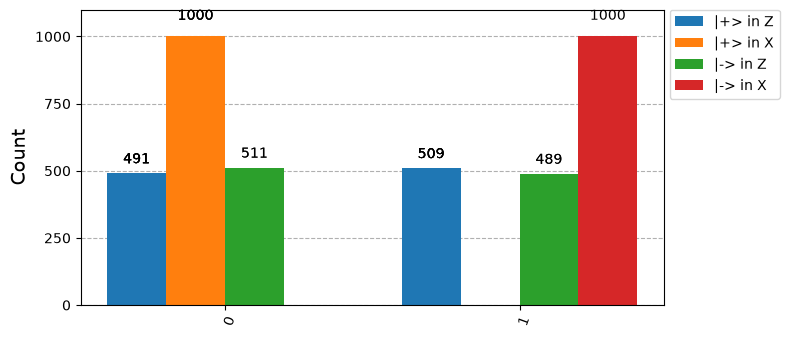

In [7]:
plus_qc = prepare(np.pi / 2, 0)        # |+>
minus_qc = prepare(np.pi / 2, np.pi)   # |->
results = {}
for name, qc in [("|+>", plus_qc), ("|->", minus_qc)]:
    for basis in "ZX":
        results[f"{name} in {basis}"] = run_counts(in_basis(qc, basis), 1000)
for k, v in results.items():
    print(f"{k:10s} {dict(sorted(v.items()))}")
plot_histogram(list(results.values()), legend=list(results.keys()), figsize=(8, 3.5))

In the Z basis the two states give the same 50/50 histogram, up to noise. In the X basis (outcome 0 means "+", 1 means "-") $|+\rangle$ always gives 0 and $|-\rangle$ always gives 1.

### Worked example 2.6: a histogram is not a state

Suppose a friend secretly tosses a coin before each shot and prepares $|0\rangle$ or $|1\rangle$. Measured in the Z basis, the histogram is 50/50, the same as for $|+\rangle$. Only the X basis shows the difference: the coin-toss qubits give 50/50 again, while $|+\rangle$ gives "+" every time.

In [8]:
coin = run_counts(in_basis(prepare(0), "Z"), 500)            # |0> for half the shots
coin_1 = run_counts(in_basis(prepare(np.pi), "Z"), 500)     # |1> for the other half
coin_z = {k: coin.get(k, 0) + coin_1.get(k, 0) for k in "01"}
coin_x0 = run_counts(in_basis(prepare(0), "X"), 500)
coin_x1 = run_counts(in_basis(prepare(np.pi), "X"), 500)
coin_x = {k: coin_x0.get(k, 0) + coin_x1.get(k, 0) for k in "01"}
print("coin toss, Z basis:", coin_z, "   coin toss, X basis:", coin_x)
print("|+>,       Z basis:", dict(sorted(results["|+> in Z"].items())), "   |+>,       X basis:", dict(sorted(results["|+> in X"].items())))

coin toss, Z basis: {'0': 500, '1': 500}    coin toss, X basis: {'0': 494, '1': 506}
|+>,       Z basis: {'0': 491, '1': 509}    |+>,       X basis: {'0': 1000}


The lesson: **one histogram in one basis does not identify a state.** To pin down a single-qubit state you need statistics in at least three bases (Z, X and Y), which give the three Bloch components. This idea, called **state tomography**, returns in later workbooks. It also explains a warning for Workbook 4: a Z-basis histogram of two qubits, on its own, cannot prove that they are entangled.

> **Note.** The simulator gave us exact 0 counts for "-" when measuring $|+\rangle$. A real device would show a few wrong outcomes because of noise. Workbook 10 covers noise.

### Summary

- A qubit state is $\alpha|0\rangle + \beta|1\rangle$ with $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2 = 1$.
- Born rule: $P(b) = \lvert\langle b|\psi\rangle\rvert^2$ for any orthonormal basis; the state then becomes $|b\rangle$.
- Global phase never matters. Relative phase matters, but only shows up in a basis other than Z.
- Bloch sphere: $|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$, with Bloch vector $(\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$. Orthogonal states are antipodal.
- X-basis measurement = apply $H$, then measure in Z.
- Shots give estimates with typical error $\sqrt{p(1-p)/N}$. A simulator samples exact probabilities; it is not hardware.

### References for this workbook

- J. D. Hidary, *Quantum Computing: An Applied Approach*, 2nd ed. (Springer, 2021): Ch. 1, Secs. 1.1 and 1.2 (superposition, the Born rule); Ch. 3, Secs. 3.5 (the Bloch sphere) and 3.6 (the measurement postulate); Ch. 12, Sec. 12.9 (the qubit as a Hilbert space); Ch. 14, Sec. 14.4 (notation for expectation values).
- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. (Cambridge, 2010): Sec. 1.2 (quantum bits, including the Bloch sphere); Sec. 1.3.3 (measurements in other bases); Secs. 2.2.1, 2.2.3, 2.2.5 and 2.2.7 (state space, measurement, projective measurement, phase).
- Y. Ding and F. T. Chong, *Quantum Computer Systems* (2020): Ch. 2, "Think Quantumly About Computing", Secs. 2.1 and 2.2.
- J. Watrous, IBM Quantum Learning, *Basics of Quantum Information*, Lesson 1 "Single systems" (quantum information; Qiskit implementation).
- Qiskit Textbook (legacy, archived 2024): chapter "Quantum States and Qubits", sections "The Atoms of Computation" and "Representing Qubit States". Its code uses older Qiskit APIs; use the versions pinned in this workbook.

# Part B: Workbook exercises

E = easy, M = medium, H = hard, Q = Qiskit task. Show your working for by-hand questions. Leave answers exact where you can (fractions, surds, multiples of $\pi$), then give a decimal.

## Easy

**E1.** Which of these are valid qubit states? Give the value of $\lvert\alpha\rvert^2 + \lvert\beta\rvert^2$ for each.
(a) $\frac{1}{\sqrt2}(|0\rangle + |1\rangle)$, (b) $\frac{1}{2}(|0\rangle + |1\rangle)$, (c) $\frac12(\sqrt3|0\rangle - i|1\rangle)$, (d) $0.6|0\rangle + 0.8i|1\rangle$, (e) $0.6|0\rangle + 0.6|1\rangle$.

**E2.** Normalise $|v\rangle = 2|0\rangle + (1-i)|1\rangle$. Then find $P(0)$ and $P(1)$.

**E3.** For $|\psi\rangle = \frac12(\sqrt3|0\rangle - i|1\rangle)$, find $P(0)$ and $P(1)$ in the Z basis. If the outcome is 1, what is the state afterwards, and what does a second Z measurement give?

**E4.** (Conceptual.) Can any experiment tell $|\psi\rangle$ apart from $i|\psi\rangle$? Can any experiment tell $|0\rangle + |1\rangle$ apart from $|0\rangle + i|1\rangle$ (both divided by $\sqrt2$)? Explain in one or two sentences each.

**E5.** Without looking at the table in Section 2.4, write down $\theta$, $\varphi$ and the Bloch vector for $|1\rangle$, $|-\rangle$ and $|{+i}\rangle$.

**E6.** (Conceptual.) Two states are orthogonal. What is the angle between their Bloch vectors? Why is this not the same as the angle between the vectors in $\mathbb{C}^2$?

## Medium

**M1.** For $|\psi\rangle = \frac12(\sqrt3|0\rangle + |1\rangle)$, find $P(+)$ and $P(-)$ in the X basis, exactly and to 4 decimal places.

**M2.** Find $\theta$, $\varphi$ and the Bloch vector of $\frac{1}{\sqrt2}\left(|0\rangle + e^{i\pi/4}|1\rangle\right)$.

**M3.** Find $\theta$, $\varphi$ and the Bloch vector of $\frac12(\sqrt3|0\rangle - i|1\rangle)$.

**M4.** The state $\frac{1}{\sqrt2}(i|0\rangle - |1\rangle)$ does not have a real first amplitude. Pull out a global phase to write it in Bloch form, and say which of the six standard states it is.

**M5.** For each of $|+\rangle$, $|-\rangle$, $|{+i}\rangle$ and $|{-i}\rangle$, give $P(0)$ in the Z basis and $P(+)$ in the X basis. Which pair cannot be told apart using only Z and X measurements? Which measurement would separate them?

**M6.** A state has $P(1) = 0.25$. You run $N = 1000$ shots. (a) What are the expected count of 1s and its standard deviation $\sqrt{Np(1-p)}$? (b) You see 280 ones. How many standard deviations is that from the expected count? Is it a cause for concern?

## Hard

**H1.** Show that $X = |+\rangle\langle +| - |-\rangle\langle -|$ and $I = |+\rangle\langle +| + |-\rangle\langle -|$. Use them to prove $P(+) = \frac{1 + \langle X\rangle}{2}$. Then show that for the Bloch-form state, $\langle X\rangle = \sin\theta\cos\varphi$.

**H2.** A "mystery" state is prepared many times. Z-basis measurement, 1000 shots: 854 zeros, 146 ones. X-basis measurement, 1000 shots: 853 "+", 147 "-". (a) Estimate $z$ and $x$. (b) Estimate $\theta$ and $\varphi$, assuming the state is pure. (c) What extra measurement would you need to be sure of the sign of $\varphi$?

**H3.** You want to estimate a probability near $p = 0.5$ with a standard error of at most $0.01$. How many shots do you need? How many for a standard error of $0.001$? What does this tell you about the cost of precise estimates?

**H4.** Let $|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$ and $|\psi^\perp\rangle = \sin\frac{\theta}{2}|0\rangle - e^{i\varphi}\cos\frac{\theta}{2}|1\rangle$. (a) Show $\langle\psi|\psi^\perp\rangle = 0$. (b) Show that $|\psi^\perp\rangle$ has Bloch angles $(\pi - \theta, \varphi + \pi)$, up to global phase. (c) Deduce that its Bloch vector is $-\vec r$.

## Qiskit tasks

**Q1.** Use `prepare` to make a state with $P(1) = 0.8$ (find the right $\theta$). Run 4000 shots in the Z basis with `run_counts`, plot the histogram, and check that your estimate of $P(1)$ is within 3 standard errors of $0.8$.

In [9]:
# Q1: your code here

**Q2.** Prepare $|+\rangle$, $|-\rangle$, $|{+i}\rangle$ and $|{-i}\rangle$. Measure each in the Z, X and Y bases with 2000 shots. Print a table of the fraction of 0 outcomes. Which states does each basis separate?

In [10]:
# Q2: your code here

**Q3.** (Mini tomography.) The function below prepares a state whose angles you do not know. Measure it in the Z, X and Y bases (4000 shots each), estimate the Bloch vector using $x \approx 2P(\text{outcome }0) - 1$ in each basis, and compare with the exact Bloch vector from `bloch_vector(Statevector(mystery()))`.

In [11]:
def mystery():
    return prepare(1.1, 0.7)

In [12]:
# Q3: your code here

# Part C: Answer key

The answer key is in the instructor edition of this workbook.